# 2.5.1 Nhiễu Gauss

Notebook đi theo thứ tự: mô tả vấn đề, chứng minh vấn đề, nhóm ảnh gặp phải, tỉ lệ ảnh gặp vấn đề, phương pháp đề xuất, chạy thực nghiệm, so sánh dự đoán trên mẫu 100 ảnh.

**Kiểm soát biến:** chỉ thay đổi phép tiền xử lý; giữ nguyên split theo `lesion_id`, seed 42–44 và cấu hình đóng băng ở `src/training.py` (ResNet-18, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WRS, flip).

**GPU RTX 3050 4 GB:** giữ AMP, `cudnn.benchmark`, ảnh cache trong RAM và flip + normalize trên GPU. Batch 32 không đổi vì sẽ phá tính so sánh.

Test không dùng để chọn phương pháp. Mọi số đọc từ `outputs/`, đầu ra lượt này ở `outputs/rerun_2.5/` và `outputs/figures/rerun_2.5/`.

In [1]:
# Chạy từ gốc repo. Mọi tính toán nằm ở src/preprocess/problem_report.py để hai notebook dùng đúng một quy trình.
import pandas as pd
from IPython.display import display
from src.preprocess import problem_report as R

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)
KEY = "noise"
D = R.load_table()
print(R.PROBLEMS[KEY]["name"], "| số ảnh:", len(D))

Nhiễu Gauss | số ảnh: 10015


## 1. Mô tả vấn đề

**Nhiễu Gauss** là biến thiên ngẫu nhiên cộng vào độ sáng từng pixel theo mô hình $g(x,y) = f(x,y) + \eta(x,y)$, $\eta \sim \mathcal N(0,\sigma^2)$ (Chương 3). Trên ảnh dermoscopy, nhiễu đến từ cảm biến và điều kiện chụp, thấy rõ ở vùng da phẳng dưới dạng hạt mịn.

**Vì sao có thể hại CNN:** nhiễu làm lẫn kết cấu thật của tổn thương như mạng sắc tố, chấm, vệt ở tần số cao.

**Vì sao có thể không hại:** ảnh gốc 600×450 được resize về 224×224 có antialias, tức đã làm trơn bớt nhiễu trước khi vào mạng.

**Cách đo (bộ đo EDA):** σ là độ lệch chuẩn của phần dư ảnh xám trừ trung vị 3×3, chỉ tính ở 20% pixel phẳng nhất. **Cờ `F_noise`:** σ > Q3 + 1,5·IQR, loại ảnh nhiều lông vì sợi lông bạc bị đo nhầm thành nhiễu.

## 2. Chứng minh vấn đề

Phần này kiểm tra ảnh nhiễu nằm ở đâu trong phân phối chung, và bộ đo có phản ứng đúng với nhiễu đã biết không.

,noise
n ảnh có đo,10015.000
trung vị,1.339
Q1,1.121
Q3,1.537
min,0.382
max,5.956
ngưỡng cờ,2.160
trung vị nhóm cờ,2.429
trung vị còn lại,1.314


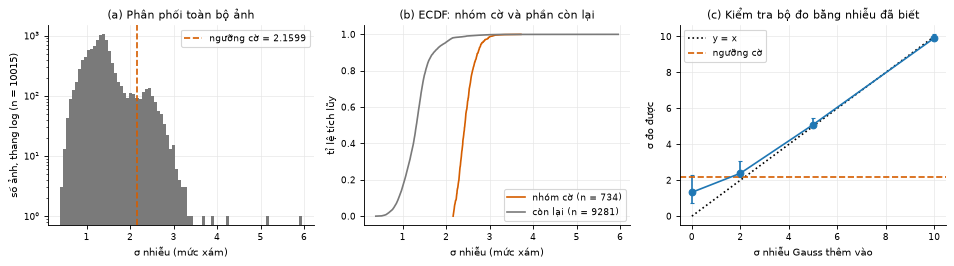

In [2]:
display(R.evidence_table(D, KEY).round(3))
R.fig_evidence(D, KEY);

**Bằng chứng độc lập với cờ.** So nhóm cờ và phần còn lại trên đúng chỉ số dùng để gắn cờ thì khác biệt là hiển nhiên, nên bảng dưới dùng chỉ số khác, một ảnh mỗi lesion. Cliff's δ: dưới 0,147 không đáng kể, dưới 0,33 nhỏ, dưới 0,474 vừa, từ đó trở lên lớn.

In [3]:
display(R.independent_evidence(D, KEY).round(3))

,chỉ số,nguồn,n cờ,n còn lại,trung vị cờ,trung vị còn lại,Cliff δ
0,σ sau resize 224 (cùng bộ đo),toàn bộ dữ liệu,706,6764,1.576,1.224,0.544
1,σ Immerkaer 600×450 (bộ đo độc lập),"train_fit, cờ vs đối chứng",460,453,1.582,0.810,0.981
2,σ Immerkaer sau resize 224,"train_fit, cờ vs đối chứng",460,453,0.859,0.599,0.802


**Ảnh minh họa, chọn có hệ thống:** 6 ảnh bị cờ và 6 ảnh thường, cách đều theo thứ tự σ. Dưới mỗi ảnh là phần dư g − trung vị 3×3 của vùng giữa, khuếch đại 8 lần để nhiễu nhìn thấy được.

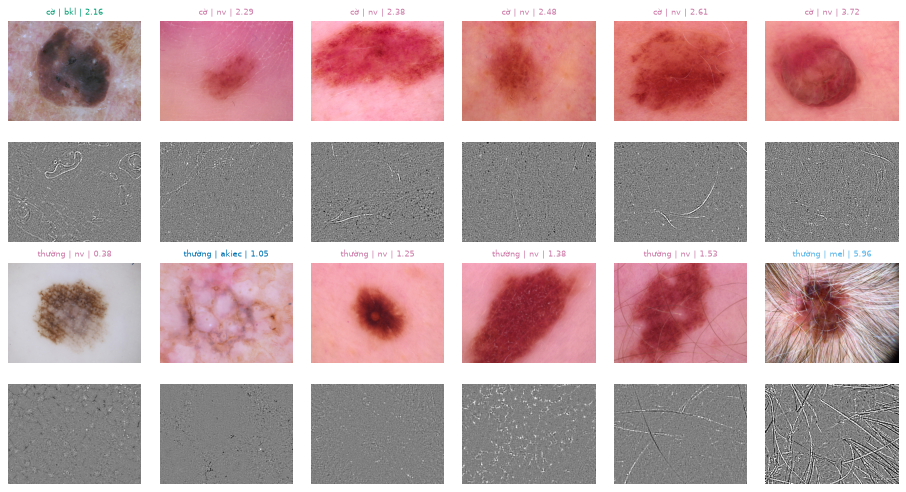

In [4]:
R.fig_examples(D, KEY);

## 3. Các nhóm ảnh gặp phải

Tỉ lệ ảnh bị cờ theo lớp bệnh, vùng cơ thể, cách gán nhãn, tuổi, giới, kèm CI95 Wilson. Kiểm định chi-square và Cramér's V tính trên một ảnh mỗi lesion, hiệu chỉnh Holm. n lớn nên p gần như luôn nhỏ, cần đọc Cramér's V. Đây là liên quan, chưa phải nguyên nhân: cờ có thể phản ánh nguồn chụp khác nhau.

,yếu tố,n lesion,chi2,p,Cramér V,p Holm
0,Lớp bệnh,7470,179.3390,0.0,0.1549,0.0
1,Vùng cơ thể,7264,132.7743,0.0,0.1352,0.0
2,Cách gán nhãn,7470,462.3404,0.0,0.2488,0.0
3,Nhóm tuổi,7418,200.9114,0.0,0.1646,0.0
4,Giới,7420,42.5575,0.0,0.0757,0.0


,yếu tố,nhóm,n ảnh,n cờ,tỉ lệ %,CI thấp %,CI cao %
0,Lớp bệnh,akiec,327,0,0.00,0.00,1.16
1,Lớp bệnh,bcc,514,3,0.58,0.20,1.70
2,Lớp bệnh,bkl,1099,43,3.91,2.92,5.23
3,Lớp bệnh,df,115,21,18.26,12.27,26.31
4,Lớp bệnh,mel,1113,21,1.89,1.24,2.87
5,Lớp bệnh,nv,6705,640,9.55,8.86,10.27
6,Lớp bệnh,vasc,142,6,4.23,1.95,8.91
7,Vùng cơ thể,abdomen,1022,112,10.96,9.19,13.02
8,Vùng cơ thể,back,2192,110,5.02,4.18,6.01
9,Vùng cơ thể,chest,407,8,1.97,1.00,3.83


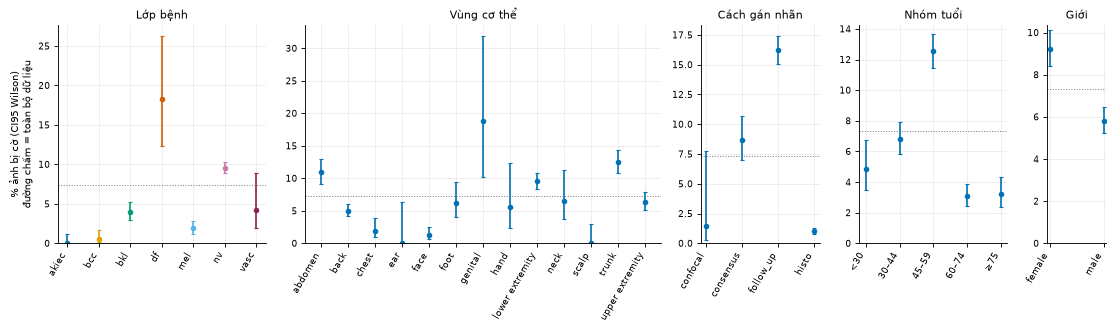

In [5]:
R.fig_groups(D, KEY);
display(R.group_tests(D, KEY).round(4))
display(R.group_rates(D, KEY).drop(columns='cột').round(2))

## 4. Tỉ lệ ảnh gặp vấn đề

Số ảnh bị cờ trên toàn bộ và từng tập, và độ nhạy theo ngưỡng để kết luận không phụ thuộc một ngưỡng duy nhất.

In [6]:
display(R.prevalence(D, KEY).round(2))
display(R.threshold_sensitivity(D, KEY).round(3))

,tập,n ảnh,n cờ,tỉ lệ %,n lesion cờ
0,toàn bộ,10015,734,7.33,731
1,train,6408,463,7.23,460
2,val,1603,132,8.23,132
3,test,2004,139,6.94,139


,quy tắc,ngưỡng σ,n cờ,tỉ lệ %
0,Q3 + 1.0·IQR,1.952,969,9.675
1,Q3 + 1.5·IQR,2.160,734,7.329
2,Q3 + 2.0·IQR,2.368,462,4.613
3,Q3 + 3.0·IQR,2.783,50,0.499


## 5. Phương pháp đề xuất

| Cấu hình | Phép xử lý (Chương 3) | Tham số | Lý do |
|---|---|---|---|
| `gauss3` | Lọc Gauss trên RGB | 3×3, nhân 1/16·[1 2 1; 2 4 2; 1 2 1] | Tối ưu cho nhiễu Gauss cộng khi tín hiệu trơn, cửa sổ nhỏ để ít mờ |
| `median3` | Lọc trung vị trên RGB | 3×3 | Giữ cạnh bậc thang tốt hơn lọc tuyến tính |
| `median5` | Lọc trung vị trên RGB | 5×5 | Đối chứng cửa sổ lớn: khử mạnh hơn nhưng dễ xóa chi tiết mảnh |

Áp dụng ở 600×450, trước resize và Normalize, giống nhau cho train, val, test. Mọi ảnh đều được lọc vì đây là bước tiền xử lý cố định của pipeline.

**Giả thuyết (đặt trước khi train lại):** resize đã khử phần lớn nhiễu nên lọc không làm macro-F1 khác rõ baseline; `median5` có thể làm giảm nhẹ do xóa chi tiết tổn thương.

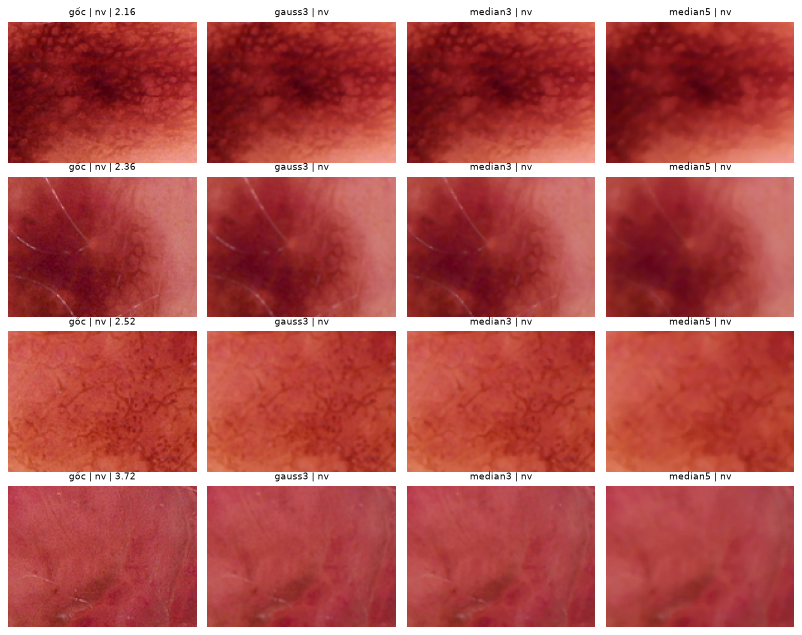

In [7]:
R.fig_before_after(D, KEY);

**Đo trên ảnh trước/sau (`train_fit`, không dùng CNN).** `sigma_imm` là σ Immerkaer ở 600×450, `sigma_imm_224` là sau resize, `lapvar_les_224_ratio` là phần phương sai Laplacian vùng tổn thương còn lại so với ảnh gốc, `contrast_ratio` là tỉ lệ tương phản còn lại. `problem` là nhóm cờ, nhóm còn lại là đối chứng.

In [8]:
display(R.image_effect(KEY))

,group,method,n,sigma_imm,sigma_imm_224,lapvar_les_224_ratio,contrast_ratio
0,problem,none,463,1.580,0.861,1.000,1.000
2,problem,gauss3,463,0.390,0.597,0.607,1.000
4,problem,median3,463,0.442,0.567,0.564,1.001
5,problem,median5,463,0.342,0.385,0.251,1.002
6,control,none,463,0.808,0.599,1.000,1.000
8,control,gauss3,463,0.337,0.477,0.656,1.000
10,control,median3,463,0.352,0.458,0.636,1.000
11,control,median5,463,0.290,0.351,0.337,1.001


## 6. Chạy thực nghiệm

Mỗi cấu hình train lại 3 seed, so với baseline ghép cặp theo seed. **Quy tắc "khác biệt rõ" (2.5.0):** |Δ| > std giữa seed của baseline, CI95 bootstrap cụm lesion không chứa 0, và cả 3 seed cùng dấu.

In [9]:
# Train ở gốc repo bằng `scripts/run_problem_experiments.py all`; seed đã có metrics.json được đọc lại nên ô này chạy nhanh.
# Chỉ gọi đúng các cấu hình của vấn đề này để notebook tự kiểm chứng đủ dữ liệu.
runs = R.train(["baseline"] + R.PROBLEMS[KEY]["configs"])
display(runs.round(4))
RES = R.result_table(KEY)
display(R.result_view(RES))
BEST = R.pick_on_val(RES)
print("Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất:", BEST)

[20:34:17] [baseline seed 42] đã có metrics.json -> đọc lại


[20:34:17] [baseline seed 43] đã có metrics.json -> đọc lại


[20:34:17] [baseline seed 44] đã có metrics.json -> đọc lại


[20:34:17] [gauss3 seed 42] đã có metrics.json -> đọc lại


[20:34:17] [gauss3 seed 43] đã có metrics.json -> đọc lại


[20:34:17] [gauss3 seed 44] đã có metrics.json -> đọc lại


... (5 outputs left out)

[20:34:17] [median5 seed 44] đã có metrics.json -> đọc lại


,name,seed,best_epoch,val_macro_f1,test_macro_f1
0,baseline,42,8,0.7002,0.6890
1,baseline,43,12,0.7143,0.6943
2,baseline,44,16,0.7341,0.6677
3,gauss3,42,20,0.7344,0.6973
4,gauss3,43,12,0.7363,0.7135
5,gauss3,44,14,0.7319,0.7002
6,median3,42,20,0.7169,0.6793
7,median3,43,8,0.7231,0.6756
8,median3,44,19,0.7279,0.6517
9,median5,42,8,0.7200,0.6549


,split,config,macro-F1,Δ macro-F1,CI95 Δ,dấu,kết luận,Δ bal. acc
0,val,baseline,0.7162 ± 0.0170,,,,,
1,val,gauss3,0.7342 ± 0.0022,+0.0180,[-0.0097; +0.0467],2+/1-,không khác biệt rõ,+0.0057
2,val,median3,0.7227 ± 0.0055,+0.0064,[-0.0139; +0.0281],2+/1-,không khác biệt rõ,-0.0121
3,val,median5,0.7193 ± 0.0032,+0.0030,[-0.0263; +0.0338],2+/1-,không khác biệt rõ,-0.0049
4,test,baseline,0.6837 ± 0.0141,,,,,
5,test,gauss3,0.7037 ± 0.0086,+0.0200,[-0.0058; +0.0476],3+/0-,không khác biệt rõ,+0.0123
6,test,median3,0.6689 ± 0.0150,-0.0148,[-0.0406; +0.0096],0+/3-,không khác biệt rõ,-0.0291
7,test,median5,0.6604 ± 0.0100,-0.0232,[-0.0528; +0.0052],1+/2-,không khác biệt rõ,-0.0373


Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất: gauss3


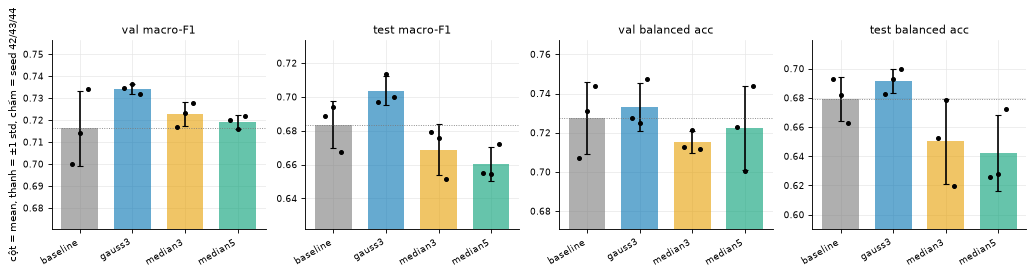

In [10]:
R.fig_results(KEY);

**F1 và recall từng lớp trên test** (trung bình 3 seed). Lớp `df`, `vasc` có ít ảnh nên dao động lớn.

In [11]:
display(R.per_class(KEY, 'test'))

F1                          recall                       
config baseline gauss3 median3 median5 baseline gauss3 median3 median5
lớp                                                                   
akiec     0.584  0.593   0.552   0.508    0.581  0.530   0.500   0.424
bcc       0.755  0.754   0.731   0.722    0.783  0.858   0.731   0.754
bkl       0.674  0.702   0.671   0.660    0.702  0.691   0.686   0.695
df        0.630  0.615   0.546   0.561    0.551  0.565   0.464   0.493
mel       0.551  0.596   0.560   0.576    0.565  0.593   0.595   0.580
nv        0.916  0.925   0.913   0.917    0.907  0.926   0.909   0.915
vasc      0.676  0.741   0.708   0.679    0.667  0.678   0.667   0.632

**Tác động riêng lên nhóm ảnh bị cờ.** DiD = Δ lỗi nhóm cờ − Δ lỗi phần còn lại. DiD âm nghĩa là phép xử lý giúp riêng nhóm cờ nhiều hơn phần còn lại.

In [12]:
display(R.target_group_effect(D, KEY).round(4))

,split,config,n nhóm cờ,lỗi baseline nhóm cờ,Δ lỗi nhóm cờ,Δ lỗi còn lại,DiD,CI thấp,CI cao
0,val,gauss3,132,0.0581,-0.0076,-0.0057,-0.0019,-0.0262,0.0225
1,val,median3,132,0.0581,-0.0025,0.0091,-0.0116,-0.0325,0.0108
2,val,median5,132,0.0581,-0.0101,0.0018,-0.0119,-0.0310,0.0070
3,test,gauss3,139,0.0839,-0.0072,-0.0175,0.0103,-0.0116,0.0331
4,test,median3,139,0.0839,0.0072,0.0036,0.0036,-0.0193,0.0297
5,test,median5,139,0.0839,-0.0168,0.0027,-0.0195,-0.0467,0.0049


## 7. So sánh dự đoán trên mẫu 100 ảnh gặp vấn đề

**Cách lấy mẫu:** rút ngẫu nhiên 100 ảnh bị cờ ở val + test, seed 42, mỗi lesion một ảnh, không nhìn dự đoán. Dùng cả val vì ảnh bị cờ ở test có thể không đủ 100, và đây là thống kê ngoài mẫu huấn luyện.

**Trước** là dự đoán của baseline, **sau** là mô hình cùng seed huấn luyện trên ảnh đã xử lý. Ba dòng `baseline seed A→B` cho biết bao nhiêu ảnh đổi đúng/sai dù không xử lý gì, đó là mức cần vượt.

In [13]:
S = R.sample_100(D, KEY)
SD = R.sample_detail(S, KEY)
print(S.split_exp.value_counts().to_dict(), S.dx.value_counts().to_dict())
display(R.sample_summary(SD, KEY).round(4))

{'val': 55, 'test': 45} {'nv': 88, 'bkl': 5, 'df': 4, 'mel': 2, 'vasc': 1}


,so sánh,đúng trước,đúng sau,sai→đúng,đúng→sai,ròng,McNemar p
0,gauss3 | seed 42,93,96,3,0,3,0.2500
1,gauss3 | seed 43,92,94,4,2,2,0.6875
2,gauss3 | seed 44,90,93,5,2,3,0.4531
3,gauss3 | đa số 3 seed,92,96,4,0,4,0.1250
4,median3 | seed 42,93,92,1,2,-1,1.0000
5,median3 | seed 43,92,95,5,2,3,0.4531
6,median3 | seed 44,90,91,4,3,1,1.0000
7,median3 | đa số 3 seed,92,94,3,1,2,0.6250
8,median5 | seed 42,93,95,3,1,2,0.6250
9,median5 | seed 43,92,93,2,1,1,1.0000


**Xác suất của lớp đúng thay đổi thế nào.** Kiểm định dấu hạng Wilcoxon ghép theo ảnh, hiệu chỉnh Holm.

,config,Δ prob TB,Δ prob trung vị,số ảnh tăng,số ảnh giảm,Wilcoxon p,p Holm
0,gauss3,0.0310,0.0027,80,20,0.0000,0.0000
1,median3,-0.0041,-0.0023,34,66,0.0075,0.0151
2,median5,0.0230,0.0001,50,50,0.1330,0.1330


,n,đúng trước (đa số),đúng sau (đa số)
dx,,,
bkl,5,3,4
df,4,2,4
mel,2,1,1
nv,88,85,86
vasc,1,1,1


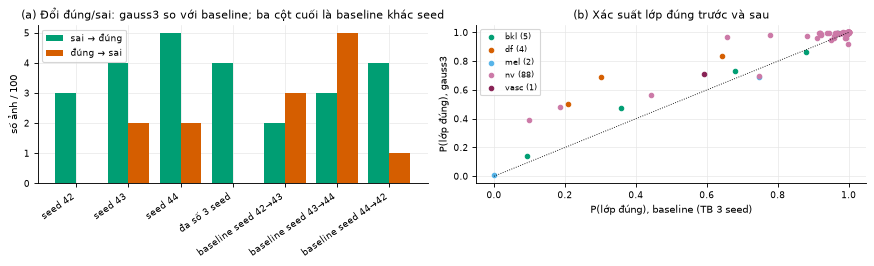

In [14]:
display(R.prob_change(SD, KEY).round(4))
display(R.sample_by_class(SD, BEST))
R.fig_sample(SD, KEY, BEST);

**Ảnh đổi đúng/sai theo đa số 3 seed** (cấu hình `BEST`, tối đa 4 ảnh mỗi chiều, lấy theo thứ tự `image_id`).

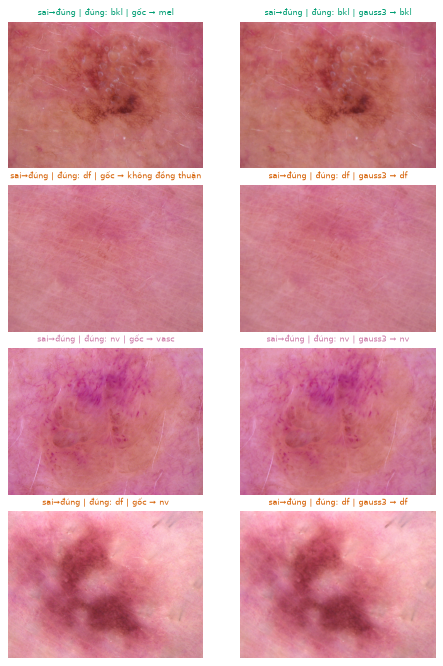

In [15]:
R.fig_sample_grid(SD, KEY, BEST);

## 8. Nhận xét

Số liệu lấy từ các bảng ở mục 2–7, file gốc ở `outputs/rerun_2.5/`. Trục y của hình kết quả ở mục 6 không bắt đầu từ 0 nên cột nhìn chênh nhiều hơn thực tế, cần đọc số trong bảng.

**Quan sát**

- **Mức độ vấn đề:** 734/10.015 ảnh bị cờ (7,33%). Tỉ lệ này đổi từ 9,68% xuống 0,50% khi hệ số IQR đi từ 1 đến 3, nên con số phụ thuộc ngưỡng.
- **Bộ đo độc lập xác nhận khác biệt:** σ Immerkaer của nhóm cờ so với đối chứng là 1,582 và 0,810 (Cliff's δ 0,981). Sau resize 224, chênh lệch thu hẹp còn 0,859 và 0,599 (δ 0,802), tức resize làm giảm nhưng không xóa hết khác biệt.
- **Nhóm ảnh:** yếu tố liên quan mạnh nhất là cách gán nhãn (Cramér's V 0,249): `follow_up` 16,23%, `histo` 1,01%. Theo lớp, `df` 18,26%, `nv` 9,55%, `akiec` 0%.
- **Macro-F1, 3 seed:** cả 3 cấu hình đều "không khác biệt rõ" với baseline trên val và test. Trên test, baseline đạt 0,6837 ± 0,0141.

| Cấu hình | Δ macro-F1 test | CI95 | Dấu theo seed | Δ balanced acc test |
|---|---|---|---|---|
| `gauss3` | +0,0200 | [−0,0058; +0,0476] | 3+/0− | +0,0123 |
| `median3` | −0,0148 | [−0,0406; +0,0096] | 0+/3− | −0,0291 |
| `median5` | −0,0232 | [−0,0528; +0,0052] | 1+/2− | −0,0373 |

- `gauss3` đạt hai điều kiện của quy tắc 2.5.0 trên test (|Δ| lớn hơn std baseline, cả 3 seed cùng dấu) nhưng CI95 vẫn chứa 0.
- **Riêng nhóm cờ:** DiD của `gauss3` là −0,0019 trên val (CI [−0,0262; +0,0225]) và +0,0103 trên test (CI [−0,0116; +0,0331]). Không có bằng chứng phép lọc giúp riêng nhóm nhiễu nhiều hơn phần còn lại. Lỗi baseline ở nhóm cờ chỉ 5,8% (val) và 8,4% (test).
- **Mẫu 100 ảnh, `gauss3`:** theo đa số 3 seed, số ảnh đúng từ 92 lên 96 (4 sai→đúng, 0 đúng→sai, McNemar p = 0,125). Theo từng seed, mức tăng ròng là +2 đến +3 ảnh. Đổi seed của chính baseline cũng cho mức ròng từ −2 đến +3 ảnh.
- Xác suất của lớp đúng tăng trung bình 0,031 (trung vị 0,0027), 80 ảnh tăng và 20 ảnh giảm, Wilcoxon sau Holm p < 0,0001. Lớp `df` đúng từ 2/4 lên 4/4, nhưng chỉ có 4 ảnh.
- `median3` trên cùng mẫu làm xác suất lớp đúng giảm nhẹ (TB −0,0041, 66 ảnh giảm, p Holm 0,015). `median5` không đổi rõ (p Holm 0,133).

**Đối chiếu giả thuyết**

- Giả thuyết "lọc không làm macro-F1 khác rõ baseline" **phù hợp** với kết quả theo quy tắc 2.5.0.
- Giả thuyết "`median5` có thể làm giảm nhẹ" **chưa được xác nhận theo quy tắc**: Δ âm trên test (−0,0232) và 2/3 seed giảm, nhưng CI95 chứa 0. Trên val, Δ lại là +0,0030.

**Diễn giải (thận trọng)**

- `gauss3` có thể có lợi nhỏ, nhưng dữ liệu hiện tại chưa đủ để kết luận. Vì DiD không cho thấy tác động riêng lên nhóm cờ, lợi ích nếu có cũng khó quy cho việc khử nhiễu. Một khả năng khác là mô hình nhận ít kết cấu tần số cao hơn trên toàn bộ ảnh, chưa được kiểm chứng ở đây.
- Cờ nhiễu gắn với nguồn ảnh (cả 3.704 ảnh `follow_up` đều là `nv`, theo `HAM10000_metadata.csv`), nên có thể phản ánh thiết bị hoặc quy trình chụp hơn là chất lượng ảnh gây lỗi cho CNN. Đây là liên quan, chưa phải nguyên nhân.
- Lọc trung vị giữ lại ít chi tiết vùng tổn thương hơn (phương sai Laplacian còn 0,564 với `median3`, 0,251 với `median5`, so với 0,607 của `gauss3`). Điều này có thể liên quan tới Δ âm của `median3`, `median5`, nhưng thí nghiệm không tách riêng được nguyên nhân.

**Hạn chế**

- Mẫu 100 ảnh có 55 ảnh từ val, mà `gauss3` được chọn theo val, nên kết quả trên mẫu có thể lạc quan một phần.
- Mẫu gồm 88 ảnh `nv` và baseline đã đúng 92 ảnh, nên dư địa cải thiện chỉ 8 ảnh và kết quả gần như không nói được gì về các lớp hiếm.
- "Sau" là mô hình train lại trên ảnh đã lọc, nên chênh lệch gồm cả tác động của ảnh và của việc train lại.

**Quyết định cho pipeline:** chưa có đủ bằng chứng để đưa khử nhiễu vào pipeline như một cải thiện. `gauss3` là ứng viên duy nhất đáng kiểm tra tiếp khi ghép pipeline ở 2.6, chọn theo val. Không dùng `median3` và `median5`.